## TP2: Entraînement et évaluation d’un modèle YOLO

In [2]:
pip install ultralytics matplotlib


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [16]:
from pathlib import Path

WORKSPACE = Path("/workspaces/TP2_Labellisation")

print("Dossier de travail :", WORKSPACE)
print("\nContenu du projet :")

for element in sorted(WORKSPACE.iterdir()):
    print("📁" if element.is_dir() else "📄", element.name)

Dossier de travail : /workspaces/TP2_Labellisation

Contenu du projet :
📁 .git
📁 .ipynb_checkpoints
📄 README.md
📁 TP2_Mame_Anta_SARR&&Favour_Tabitha_Gaglozou_YOLO
📄 Untitled.ipynb


In [17]:
from pathlib import Path
import zipfile

# Dossier du projet TP2
PROJECT_DIR = Path(
    "/workspaces/TP2_Labellisation/"
    "TP2_Mame_Anta_SARR&&Favour_Tabitha_Gaglozou_YOLO"
)

print("Dossier du projet :", PROJECT_DIR)
print("Existe :", PROJECT_DIR.is_dir())

# Rechercher les archives ZIP
zip_files = list(PROJECT_DIR.rglob("*.zip"))

print("\nArchives ZIP trouvées :", len(zip_files))

for fichier in zip_files:
    print("Nom :", fichier.name)
    print("Chemin :", fichier)
    print("Taille :", round(fichier.stat().st_size / (1024**2), 2), "Mo")

Dossier du projet : /workspaces/TP2_Labellisation/TP2_Mame_Anta_SARR&&Favour_Tabitha_Gaglozou_YOLO
Existe : True

Archives ZIP trouvées : 1
Nom : dataset_fruits.zip
Chemin : /workspaces/TP2_Labellisation/TP2_Mame_Anta_SARR&&Favour_Tabitha_Gaglozou_YOLO/dataset_fruits.zip
Taille : 28.54 Mo


In [18]:
if len(zip_files) == 1:
    ZIP_PATH = zip_files[0]

    with zipfile.ZipFile(ZIP_PATH, "r") as archive:
        fichiers = archive.namelist()

        print("Archive :", ZIP_PATH.name)
        print("Nombre d'éléments :", len(fichiers))

        print("\nStructure de l'archive :")

        for fichier in fichiers[:50]:
            print(fichier)

elif len(zip_files) == 0:
    print("Aucune archive ZIP trouvée.")

else:
    print("Plusieurs archives trouvées :")
    for i, fichier in enumerate(zip_files):
        print(i, fichier.name)

Archive : dataset_fruits.zip
Nombre d'éléments : 1229

Structure de l'archive :
dataset_fruits/
dataset_fruits/.DS_Store
__MACOSX/dataset_fruits/._.DS_Store
dataset_fruits/images/
dataset_fruits/labels/
dataset_fruits/data.yaml
__MACOSX/dataset_fruits/._data.yaml
dataset_fruits/images/.DS_Store
__MACOSX/dataset_fruits/images/._.DS_Store
dataset_fruits/images/test/
dataset_fruits/images/train/
dataset_fruits/images/val/
dataset_fruits/labels/.DS_Store
__MACOSX/dataset_fruits/labels/._.DS_Store
dataset_fruits/labels/test/
dataset_fruits/labels/train/
dataset_fruits/labels/val/
dataset_fruits/images/test/image294.jpg
__MACOSX/dataset_fruits/images/test/._image294.jpg
dataset_fruits/images/test/.DS_Store
__MACOSX/dataset_fruits/images/test/._.DS_Store
dataset_fruits/images/test/image293.jpg
__MACOSX/dataset_fruits/images/test/._image293.jpg
dataset_fruits/images/test/image292.jpg
__MACOSX/dataset_fruits/images/test/._image292.jpg
dataset_fruits/images/test/image9.jpg
__MACOSX/dataset_fruit

In [19]:
from pathlib import Path
import zipfile

# Dossier de travail
PROJECT_DIR = Path(
    "/workspaces/TP2_Labellisation/"
    "TP2_Mame_Anta_SARR&&Favour_Tabitha_Gaglozou_YOLO"
)

ZIP_PATH = PROJECT_DIR / "dataset_fruits.zip"

# Dossier où sera extrait le dataset
DATASET_DIR = PROJECT_DIR / "dataset_fruits"

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    for fichier in archive.infolist():

        nom = Path(fichier.filename)

        # Ignorer les fichiers parasites macOS
        if (
            "__MACOSX" in nom.parts
            or ".DS_Store" in nom.parts
            or nom.name.startswith("._")
        ):
            continue

        # Empêcher l'extraction hors du projet
        destination = (PROJECT_DIR / nom).resolve()
        if not destination.is_relative_to(PROJECT_DIR.resolve()):
            raise ValueError(f"Chemin non autorisé : {nom}")

        if fichier.is_dir():
            destination.mkdir(parents=True, exist_ok=True)
        else:
            destination.parent.mkdir(parents=True, exist_ok=True)
            with archive.open(fichier) as source:
                with open(destination, "wb") as cible:
                    import shutil
                    shutil.copyfileobj(source, cible)

print("Extraction terminée !")
print("Dataset :", DATASET_DIR)
print("Dataset trouvé :", DATASET_DIR.is_dir())

Extraction terminée !
Dataset : /workspaces/TP2_Labellisation/TP2_Mame_Anta_SARR&&Favour_Tabitha_Gaglozou_YOLO/dataset_fruits
Dataset trouvé : True


In [20]:
from pathlib import Path

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

total_images = 0
total_labels = 0

print("VÉRIFICATION DU DATASET")
print("=" * 50)

for split in ["train", "val", "test"]:

    images_dir = DATASET_DIR / "images" / split
    labels_dir = DATASET_DIR / "labels" / split

    images = [
        f for f in images_dir.iterdir()
        if f.suffix.lower() in extensions
    ]

    labels = list(labels_dir.glob("*.txt"))

    total_images += len(images)
    total_labels += len(labels)

    print(f"\n{split.upper()}")
    print("Images :", len(images))
    print("Annotations :", len(labels))

print("\n" + "=" * 50)
print("TOTAL IMAGES :", total_images)
print("TOTAL ANNOTATIONS :", total_labels)

VÉRIFICATION DU DATASET

TRAIN
Images : 256
Annotations : 256

VAL
Images : 22
Annotations : 22

TEST
Images : 22
Annotations : 22

TOTAL IMAGES : 300
TOTAL ANNOTATIONS : 300


In [21]:
from pathlib import Path

RTF_PATH = DATASET_DIR / "data.yaml"

print("Fichier data.rtf trouvé :", RTF_PATH.exists())

if RTF_PATH.exists():
    contenu = RTF_PATH.read_text(
        encoding="utf-8",
        errors="replace"
    )
    print(contenu[:3000])

Fichier data.rtf trouvé : True
{\rtf1\ansi\ansicpg1252\cocoartf2580
\cocoatextscaling0\cocoaplatform0{\fonttbl\f0\froman\fcharset0 Times-Roman;\f1\fmodern\fcharset0 Courier;}
{\colortbl;\red255\green255\blue255;\red31\green43\blue60;\red0\green0\blue0;}
{\*\expandedcolortbl;;\cssrgb\c16078\c22353\c30196;\cssrgb\c0\c0\c0;}
{\*\listtable{\list\listtemplateid1\listhybrid{\listlevel\levelnfc23\levelnfcn23\leveljc0\leveljcn0\levelfollow0\levelstartat0\levelspace360\levelindent0{\*\levelmarker \{none\}.}{\leveltext\leveltemplateid1\'01.;}{\levelnumbers;}\fi-360\li720\lin720 }{\listname ;}\listid1}}
{\*\listoverridetable{\listoverride\listid1\listoverridecount0\ls1}}
\paperw11900\paperh16840\margl1440\margr1440\vieww11520\viewh8400\viewkind0
\deftab720
\pard\tx220\tx720\pardeftab720\li720\fi-720\partightenfactor0
\ls1\ilvl0
\f0\fs24 \cf2 {\listtext	.	}\expnd0\expndtw0\kerning0
path: /Users/Mac/Downloads/dataset_fruits \
\ls1\ilvl0\kerning1\expnd0\expndtw0 {\listtext	.	}\expnd0\expndtw0\kernin

In [22]:
from pathlib import Path

DATASET_DIR = Path(
    "/workspaces/TP2_Labellisation/"
    "TP2_Mame_Anta_SARR&&Favour_Tabitha_Gaglozou_YOLO/"
    "dataset_fruits"
)

yaml_content = f"""path: {DATASET_DIR}
train: images/train
val: images/val
test: images/test

nc: 4

names:
  0: pomme_verte
  1: pomme_rouge
  2: orange
  3: banane
"""

yaml_path = DATASET_DIR / "data.yaml"

yaml_path.write_text(yaml_content, encoding="utf-8")

print("Fichier data.yaml créé :", yaml_path)
print("\nContenu :")
print(yaml_path.read_text())

Fichier data.yaml créé : /workspaces/TP2_Labellisation/TP2_Mame_Anta_SARR&&Favour_Tabitha_Gaglozou_YOLO/dataset_fruits/data.yaml

Contenu :
path: /workspaces/TP2_Labellisation/TP2_Mame_Anta_SARR&&Favour_Tabitha_Gaglozou_YOLO/dataset_fruits
train: images/train
val: images/val
test: images/test

nc: 4

names:
  0: pomme_verte
  1: pomme_rouge
  2: orange
  3: banane



In [23]:
from collections import Counter

classes = Counter()
erreurs = []

for split in ["train", "val", "test"]:
    labels_dir = DATASET_DIR / "labels" / split

    for fichier in labels_dir.glob("*.txt"):
        for numero, ligne in enumerate(
            fichier.read_text().splitlines(), start=1
        ):
            if not ligne.strip():
                continue

            parties = ligne.split()

            if len(parties) != 5:
                erreurs.append(
                    f"{fichier.name}, ligne {numero}: "
                    "format incorrect"
                )
                continue

            try:
                identifiant = int(parties[0])
                x, y, w, h = map(float, parties[1:])

                if identifiant not in range(4):
                    raise ValueError("classe inconnue")

                if not (
                    0 <= x <= 1 and 0 <= y <= 1
                    and 0 < w <= 1 and 0 < h <= 1
                    and x - w / 2 >= -1e-6
                    and x + w / 2 <= 1 + 1e-6
                    and y - h / 2 >= -1e-6
                    and y + h / 2 <= 1 + 1e-6
                ):
                    raise ValueError("bounding box invalide")

                classes[identifiant] += 1

            except ValueError as e:
                erreurs.append(
                    f"{fichier.name}, ligne {numero}: {e}"
                )

noms = ["pomme_verte", "pomme_rouge", "orange", "banane"]

print("ANNOTATIONS PAR CLASSE")
print("=" * 40)

for i, nom in enumerate(noms):
    print(f"{i} - {nom}: {classes[i]} objets")

print("\nNombre d'erreurs :", len(erreurs))

for erreur in erreurs[:10]:
    print(erreur)

ANNOTATIONS PAR CLASSE
0 - pomme_verte: 22 objets
1 - pomme_rouge: 121 objets
2 - orange: 140 objets
3 - banane: 180 objets

Nombre d'erreurs : 0


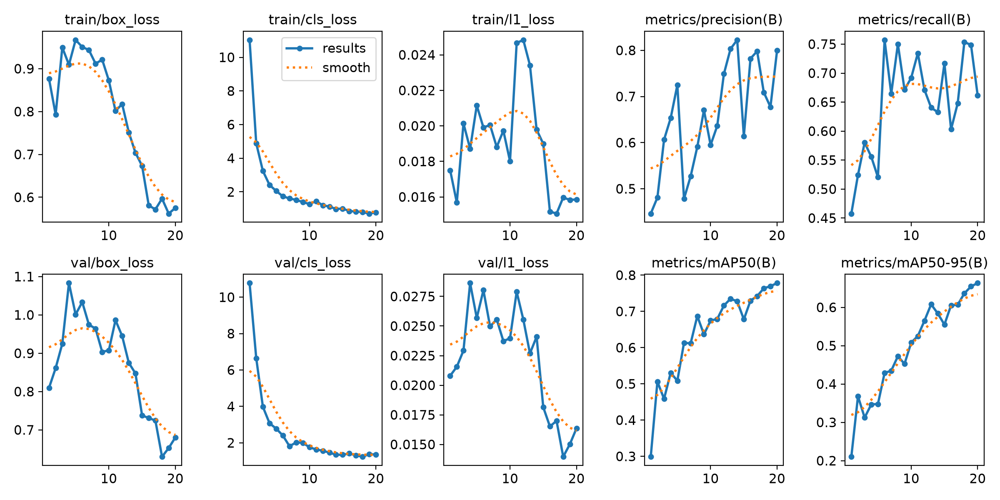

In [24]:
from pathlib import Path
from IPython.display import display, Image

RESULTS_DIR = Path(
    "/workspaces/TP2_Labellisation/"
    "TP2_Mame_Anta_SARR&&Favour_Tabitha_Gaglozou_YOLO/"
    "runs/detect/runs/fruits_detection"
)

graphique = RESULTS_DIR / "results.png"

if graphique.exists():
    display(Image(filename=str(graphique)))
else:
    print("Graphique introuvable :", graphique)


 BoxPR_curve.png


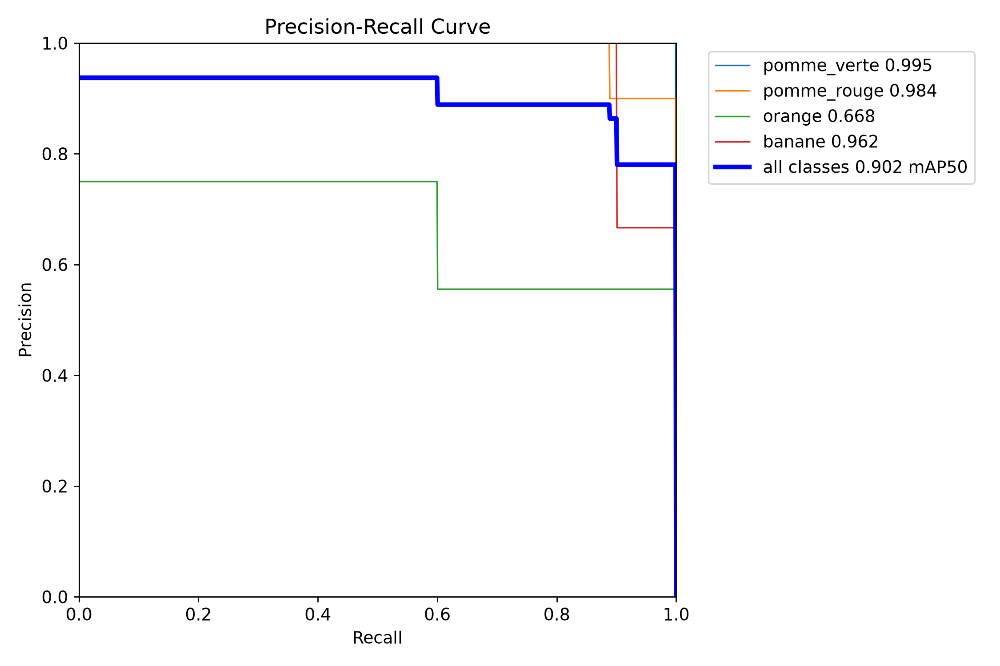


 BoxF1_curve.png


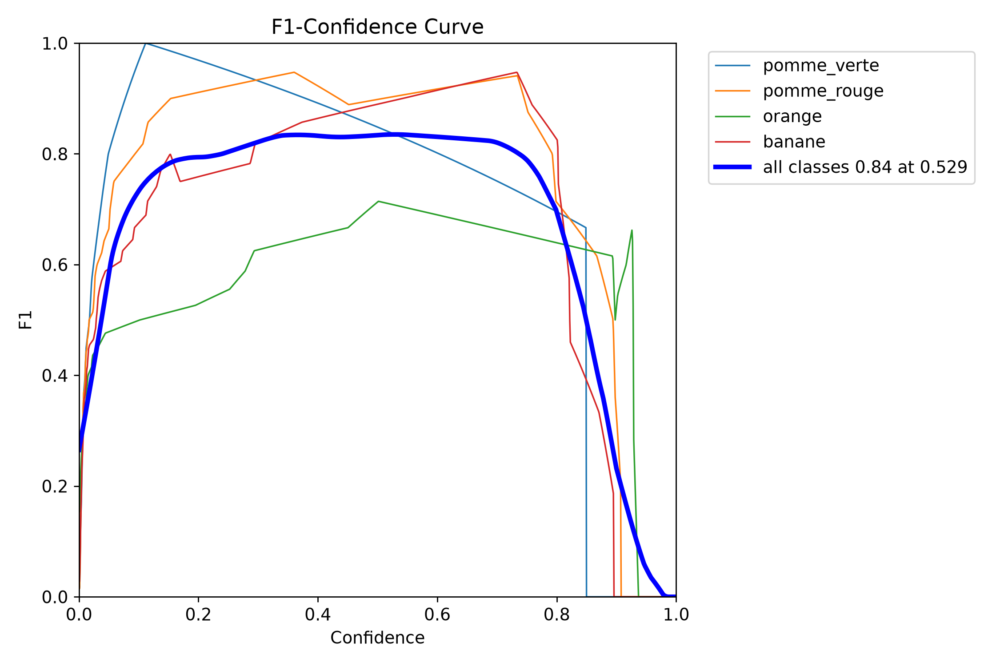


 BoxP_curve.png


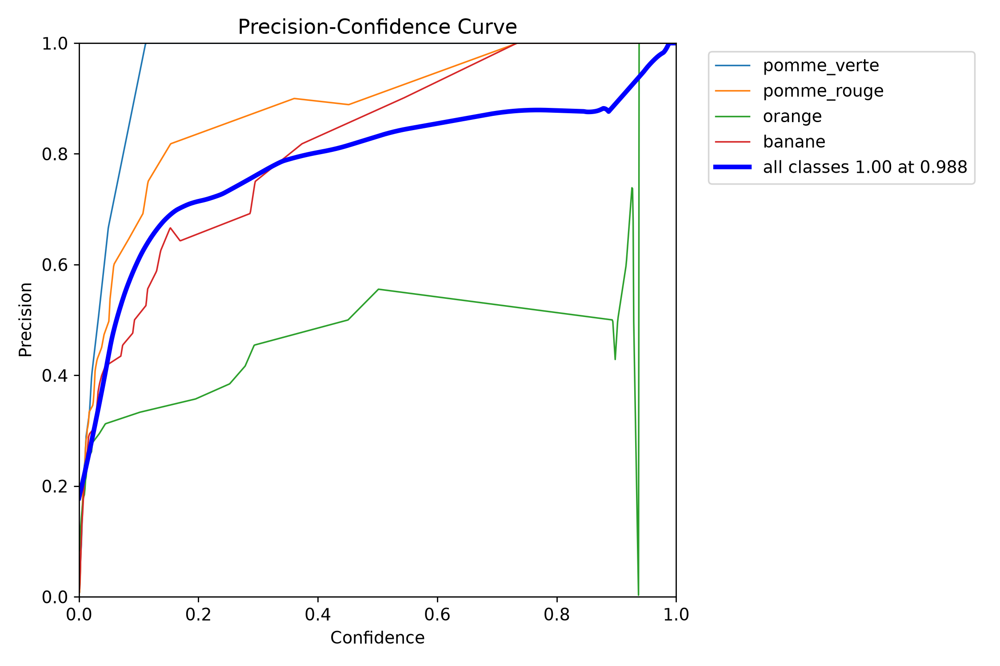


 BoxR_curve.png


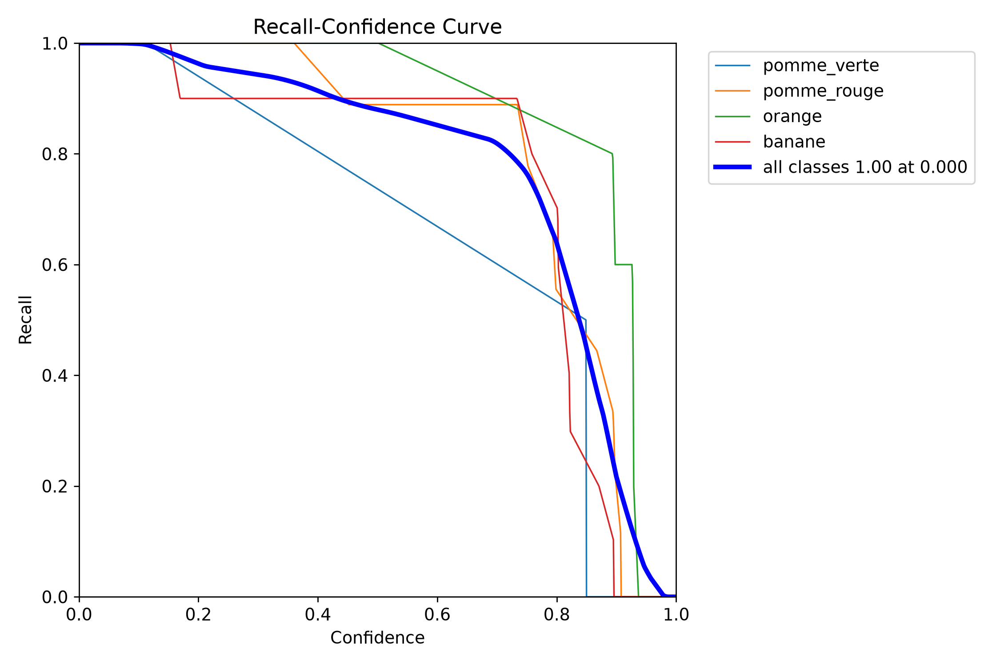


 confusion_matrix.png


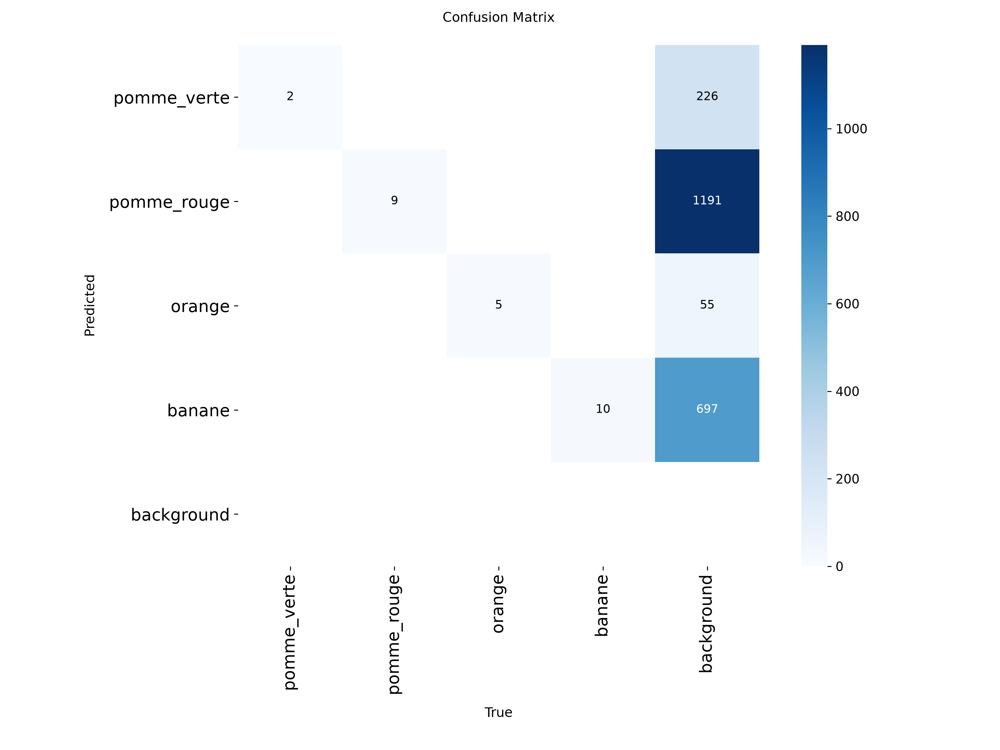


 confusion_matrix_normalized.png


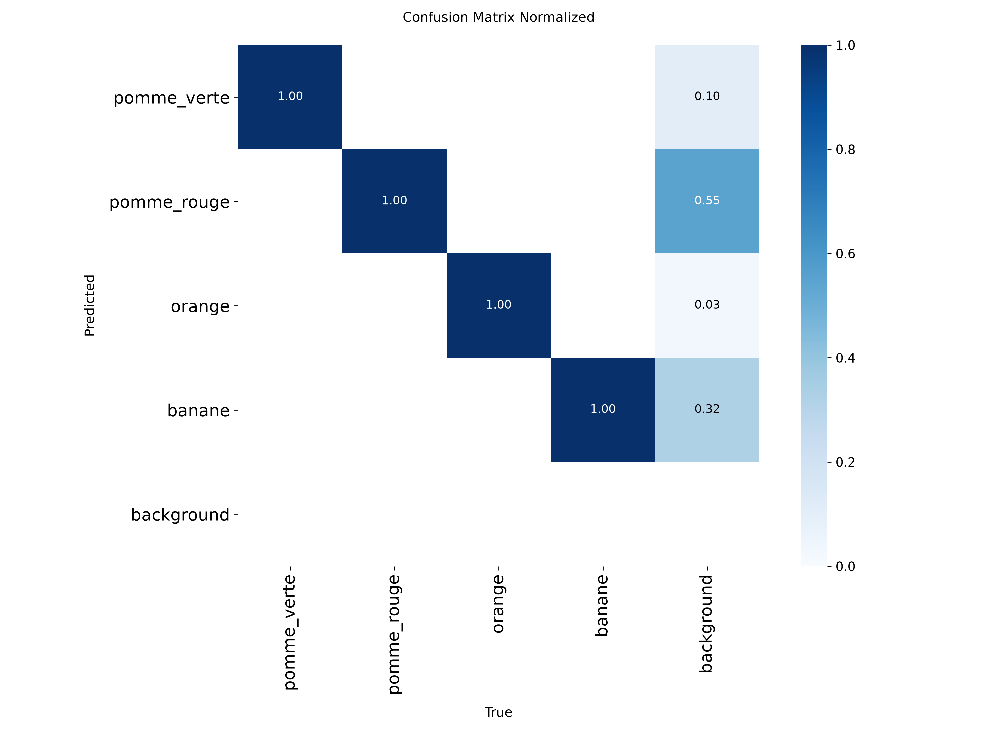

In [25]:
from pathlib import Path
from IPython.display import display, Image

results_dir = Path(
    "/workspaces/TP2_Labellisation/"
    "TP2_Mame_Anta_SARR&&Favour_Tabitha_Gaglozou_YOLO/"
    "evaluation_results/YOLO_Test"
)

graphiques = [
    "BoxPR_curve.png",
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png"
]

for nom in graphiques:
    chemin = results_dir / nom
    if chemin.exists():
        print("\n", nom)
        display(Image(filename=str(chemin), width=700))
    else:
        print("Graphique non trouvé :", nom)

Nombre d'images prédites : 22

Image : image1.jpg


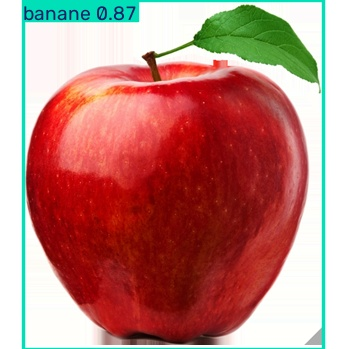


Image : image10.jpg


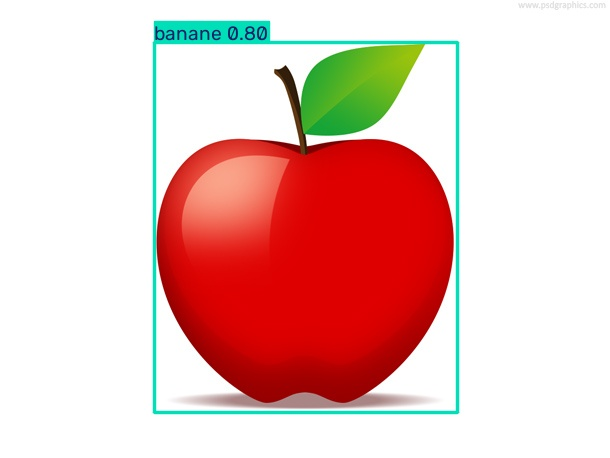


Image : image11.jpg


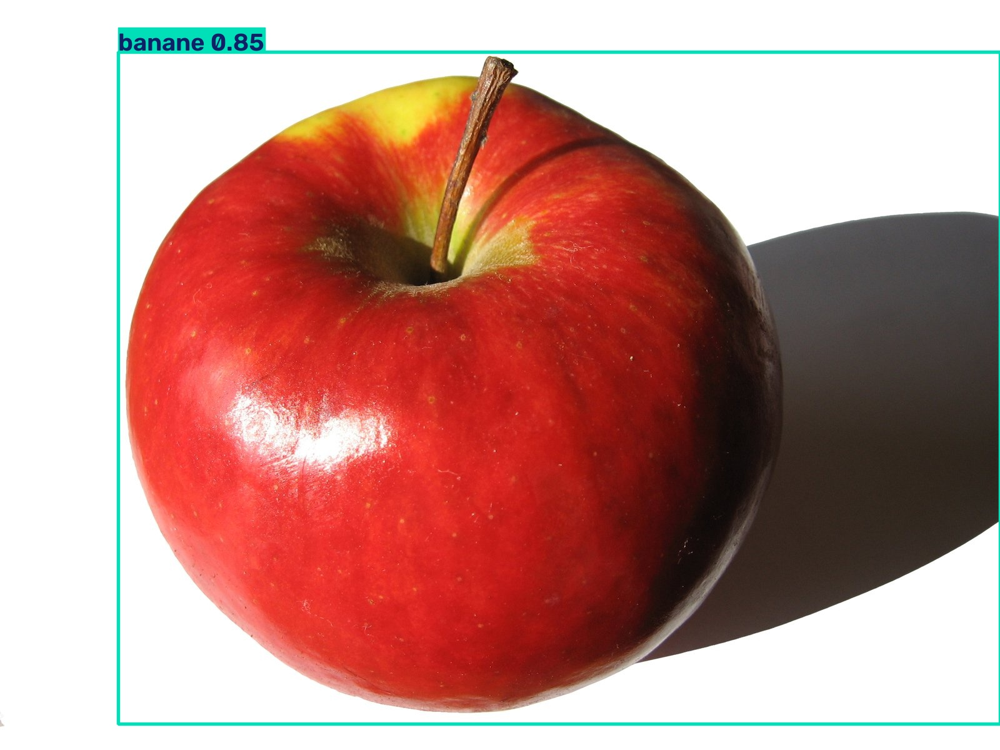


Image : image12.jpg


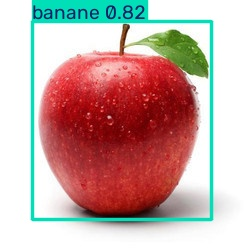


Image : image153.jpg


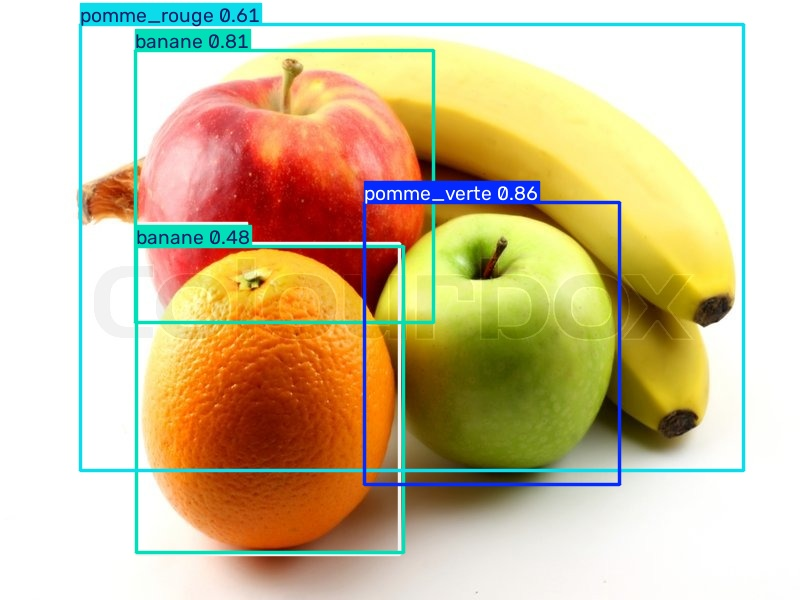


Image : image154.jpg


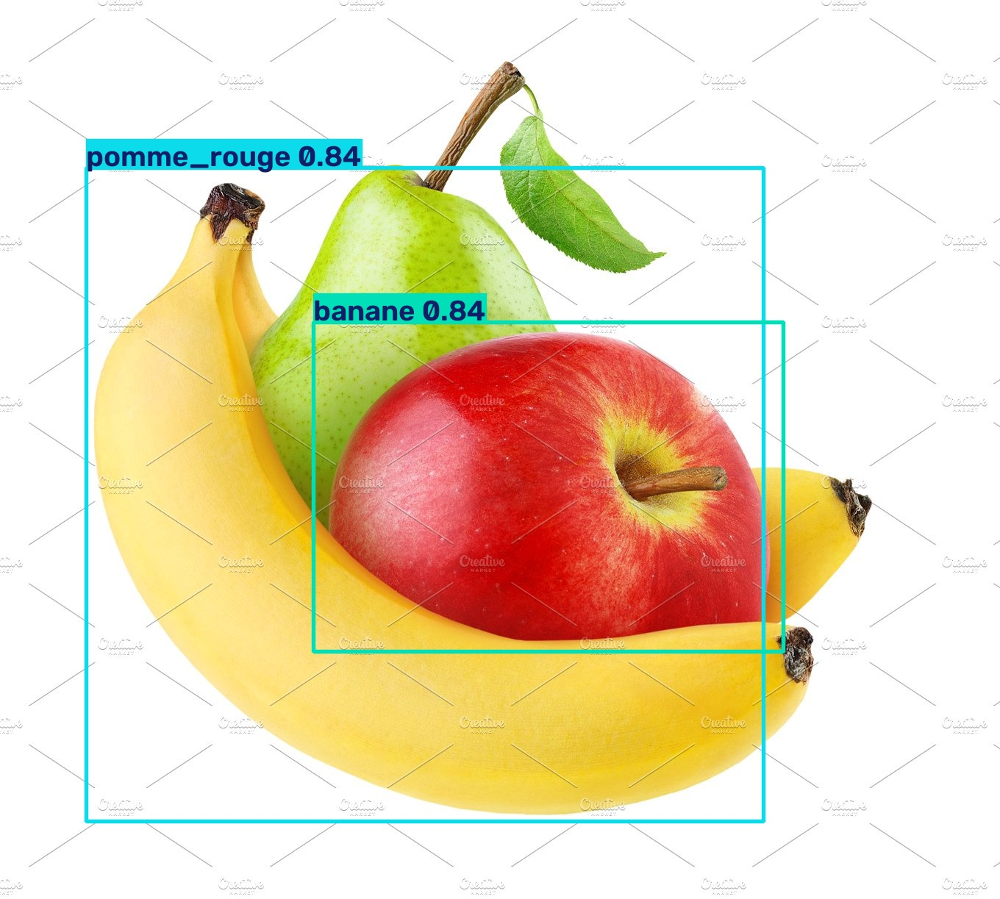


Image : image2.jpg


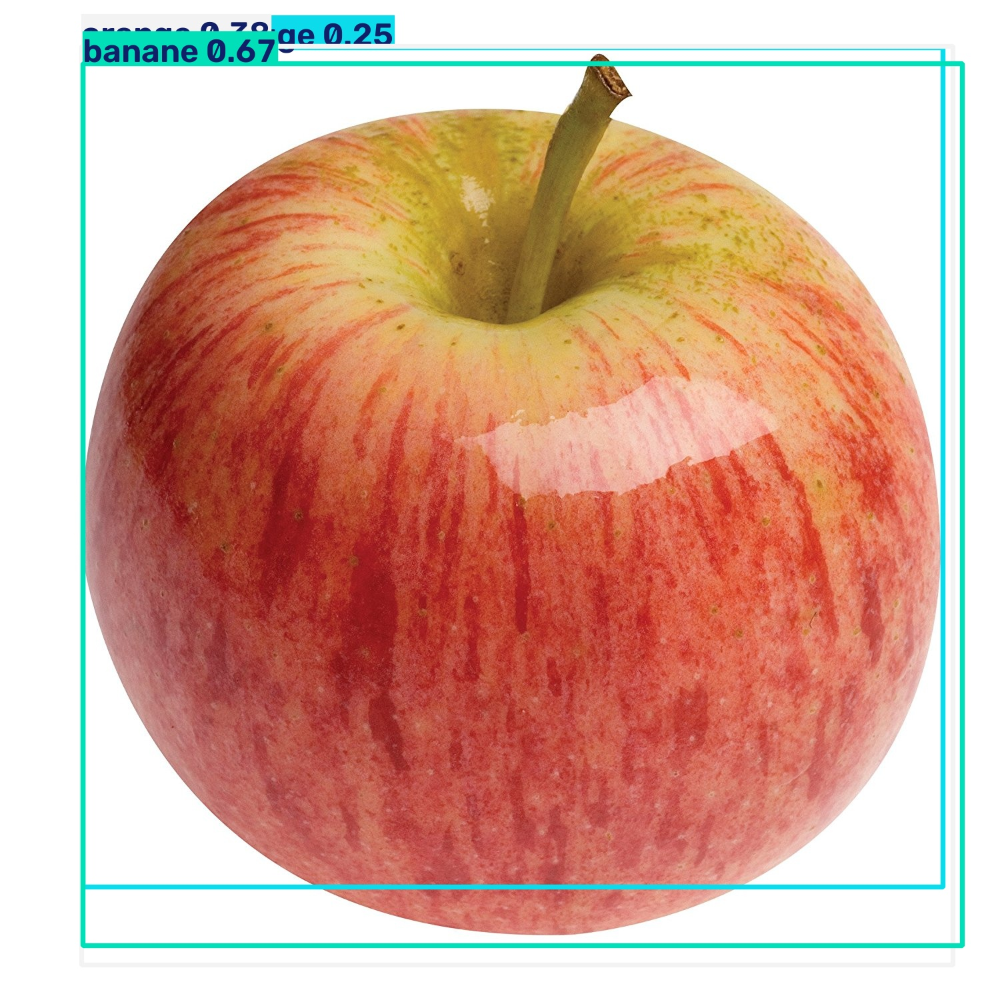


Image : image272.jpg


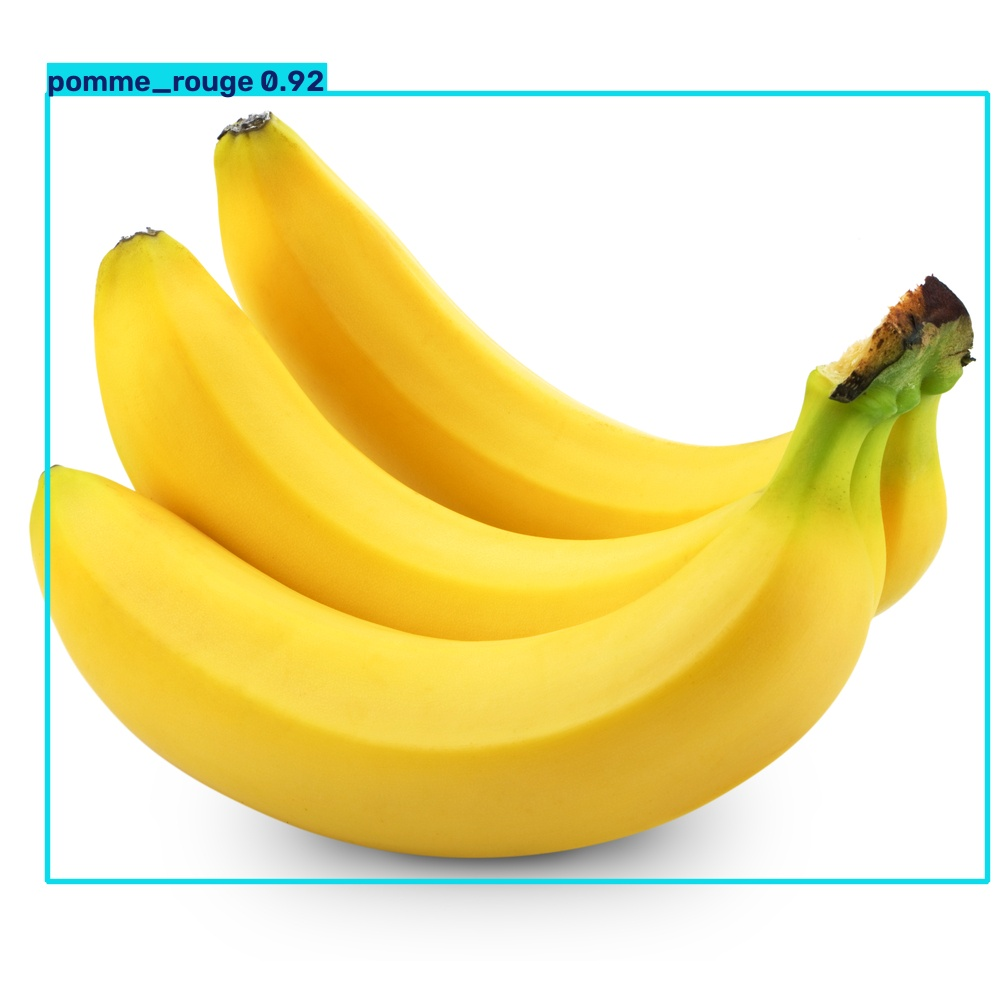


Image : image273.jpg


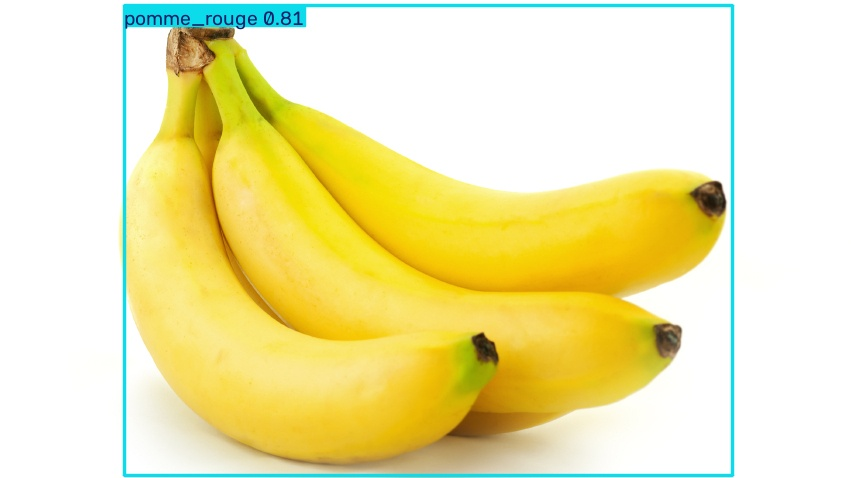


Image : image274.jpg


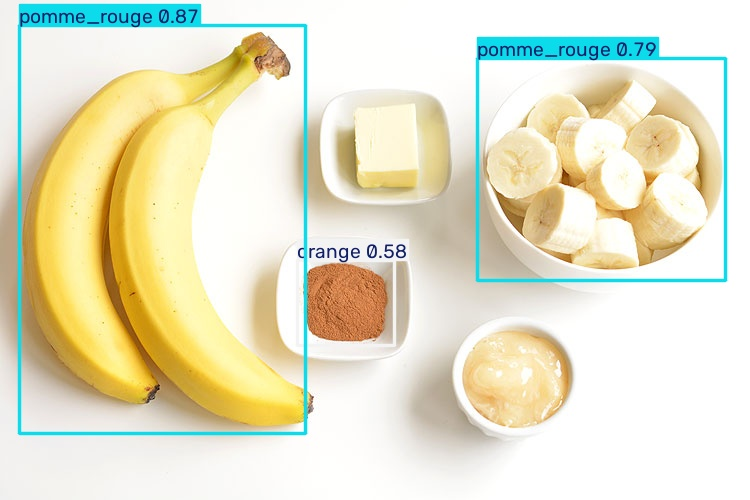

In [26]:
from pathlib import Path
from IPython.display import display, Image

project_dir = Path(
    "/workspaces/TP2_Labellisation/"
    "TP2_Mame_Anta_SARR&&Favour_Tabitha_Gaglozou_YOLO"
)

predictions_dir = project_dir / "predictions/YOLO_Predictions"

images = sorted(
    p for p in predictions_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
)

print("Nombre d'images prédites :", len(images))

for image in images[:10]:
    print("\nImage :", image.name)
    display(Image(filename=str(image), width=600))

In [29]:
%pip install pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 50.1 MB/s  0:00:00ta 0:00:01

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [30]:
from pathlib import Path
from IPython.display import display, Image
import matplotlib.pyplot as plt
import pandas as pd

PROJECT_DIR = Path(
    "/workspaces/TP2_Labellisation/"
    "TP2_Mame_Anta_SARR&&Favour_Tabitha_Gaglozou_YOLO"
)

# Dossiers d'entraînement
YOLO26_TRAIN = PROJECT_DIR / "runs/detect/runs/fruits_detection"
YOLO11_TRAIN = PROJECT_DIR / "runs_comparaison/YOLO11_fruits"

# Dossiers d'évaluation
YOLO26_EVAL = PROJECT_DIR / "evaluation_results/YOLO_Test"
YOLO11_EVAL = PROJECT_DIR / "evaluation_results/YOLO11_Test"

# Dossiers des prédictions
YOLO26_PRED = PROJECT_DIR / "predictions/YOLO_Predictions"
YOLO11_PRED = PROJECT_DIR / "predictions/YOLO11_Predictions"

print("Dossier du projet :", PROJECT_DIR)
print("Projet trouvé :", PROJECT_DIR.exists())

for nom, dossier in {
    "Entraînement YOLO26": YOLO26_TRAIN,
    "Entraînement YOLO11": YOLO11_TRAIN,
    "Évaluation YOLO26": YOLO26_EVAL,
    "Évaluation YOLO11": YOLO11_EVAL,
    "Prédictions YOLO26": YOLO26_PRED,
    "Prédictions YOLO11": YOLO11_PRED,
}.items():
    print(f"{nom}: {'OK' if dossier.exists() else 'Pas encore disponible'}")

Dossier du projet : /workspaces/TP2_Labellisation/TP2_Mame_Anta_SARR&&Favour_Tabitha_Gaglozou_YOLO
Projet trouvé : True
Entraînement YOLO26: OK
Entraînement YOLO11: OK
Évaluation YOLO26: OK
Évaluation YOLO11: OK
Prédictions YOLO26: OK
Prédictions YOLO11: OK



===== COURBES D'ENTRAÎNEMENT YOLO26n =====


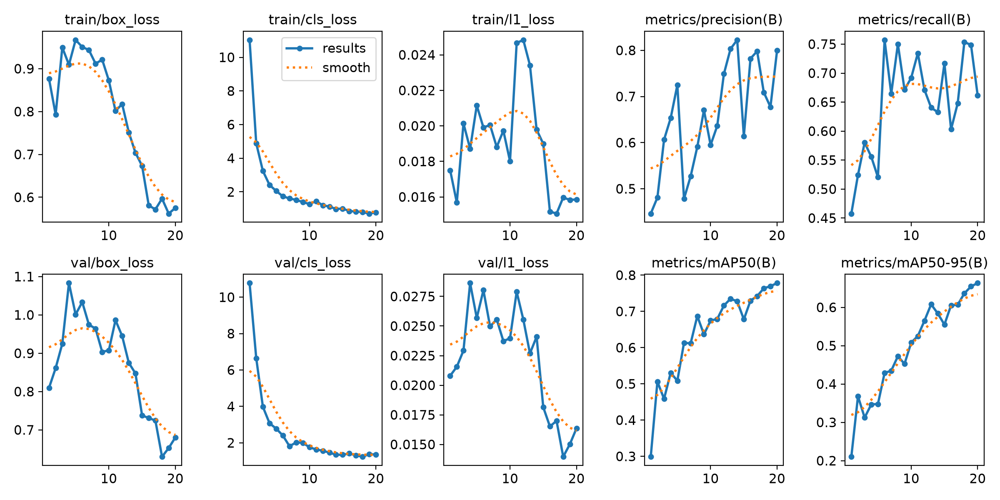


===== COURBES D'ENTRAÎNEMENT YOLO11n =====


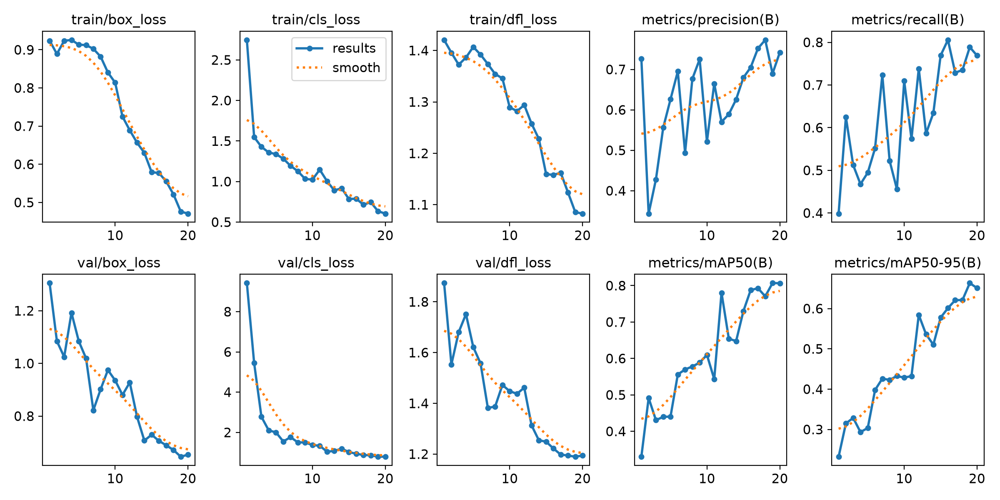

In [31]:
for nom, dossier in {
    "YOLO26n": YOLO26_TRAIN,
    "YOLO11n": YOLO11_TRAIN
}.items():

    print(f"\n===== COURBES D'ENTRAÎNEMENT {nom} =====")

    fichier = dossier / "results.png"

    if fichier.exists():
        display(Image(filename=str(fichier), width=1000))
    else:
        print("Graphique non trouvé :", fichier)


========== YOLO26n ==========

 BoxPR_curve.png


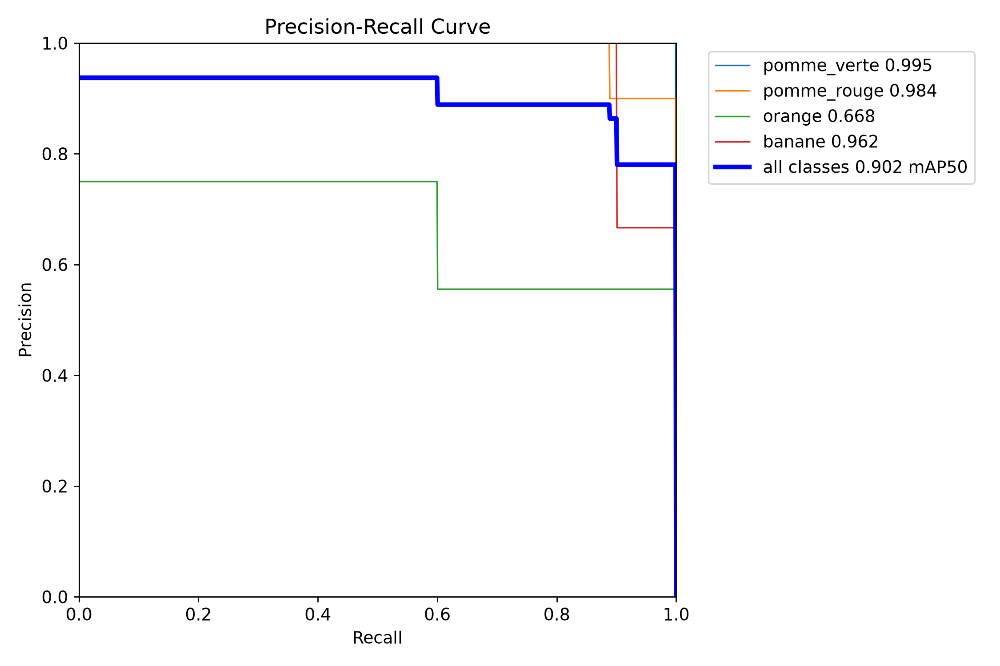


 BoxF1_curve.png


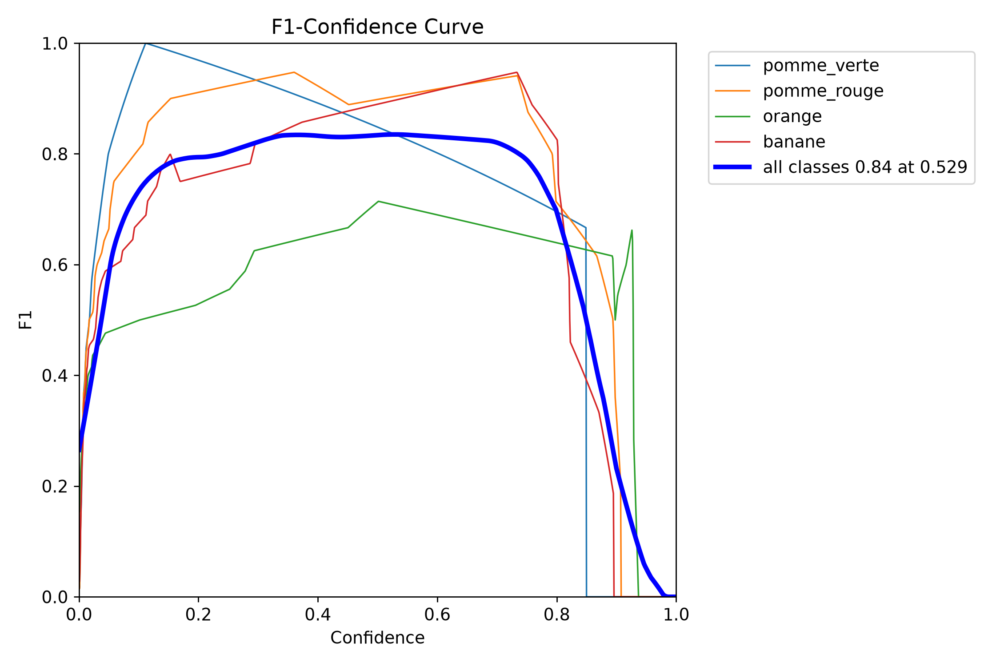


 BoxP_curve.png


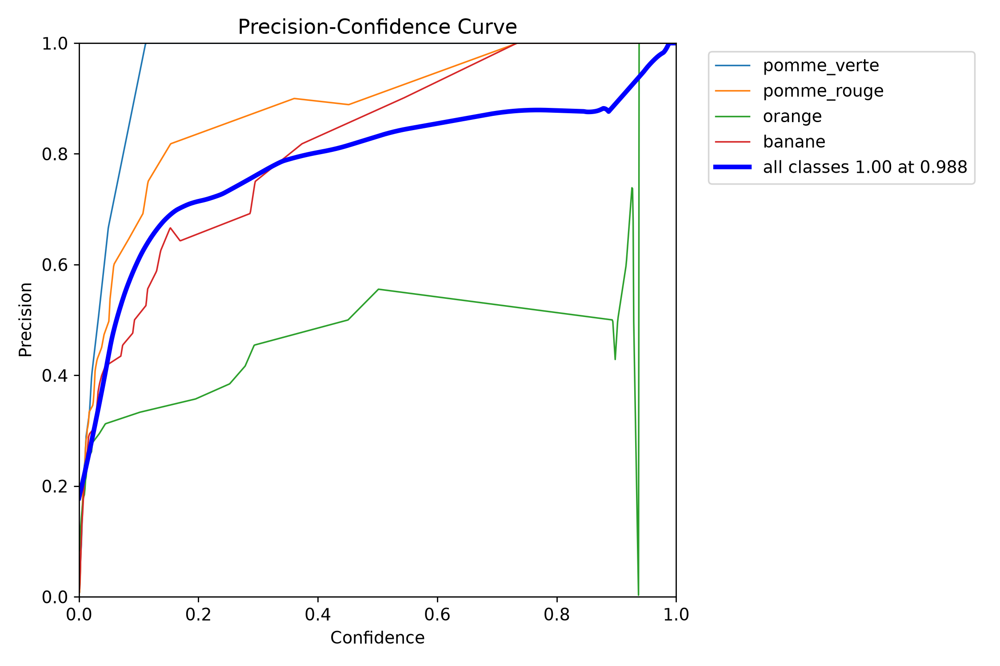


 BoxR_curve.png


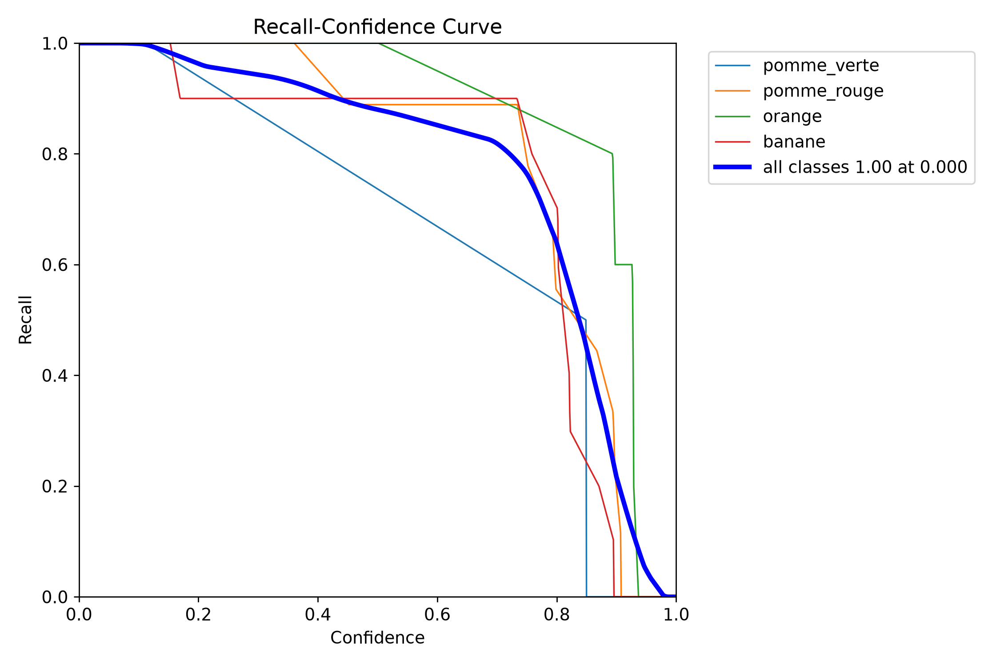


========== YOLO11n ==========

 BoxPR_curve.png


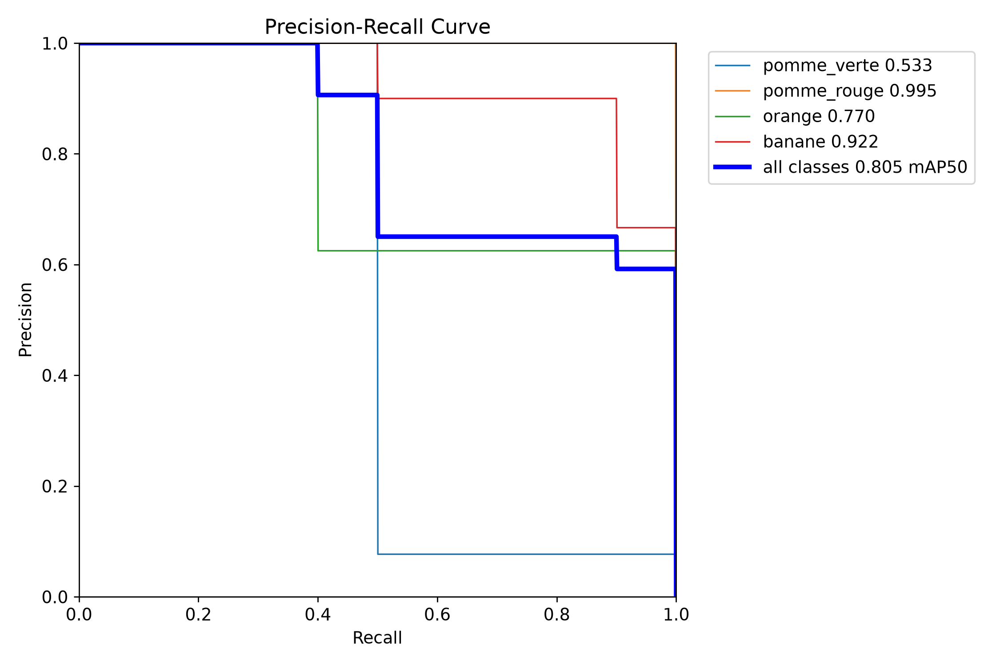


 BoxF1_curve.png


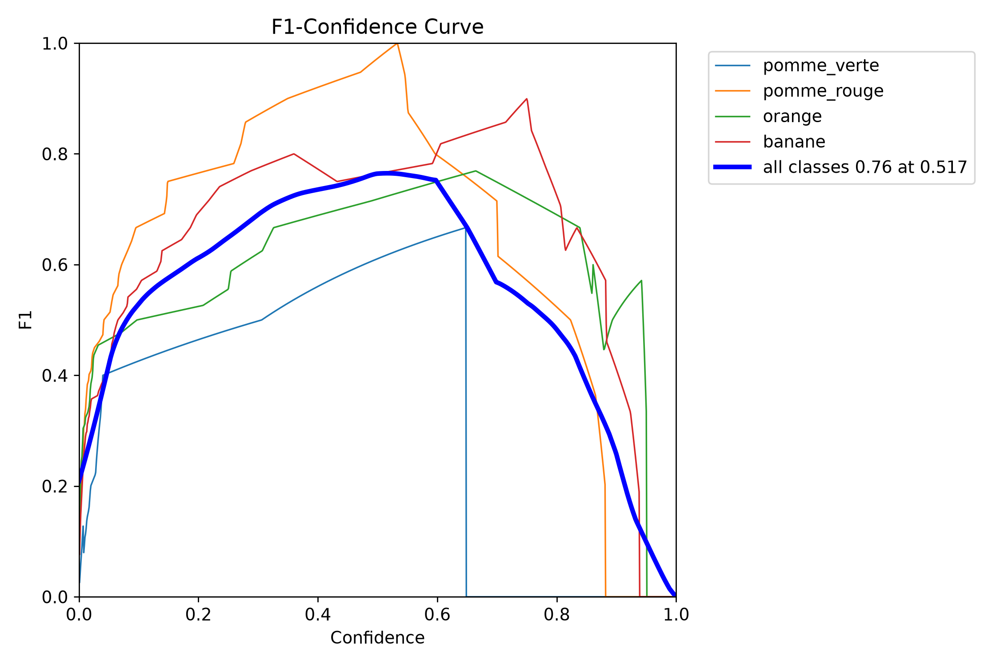


 BoxP_curve.png


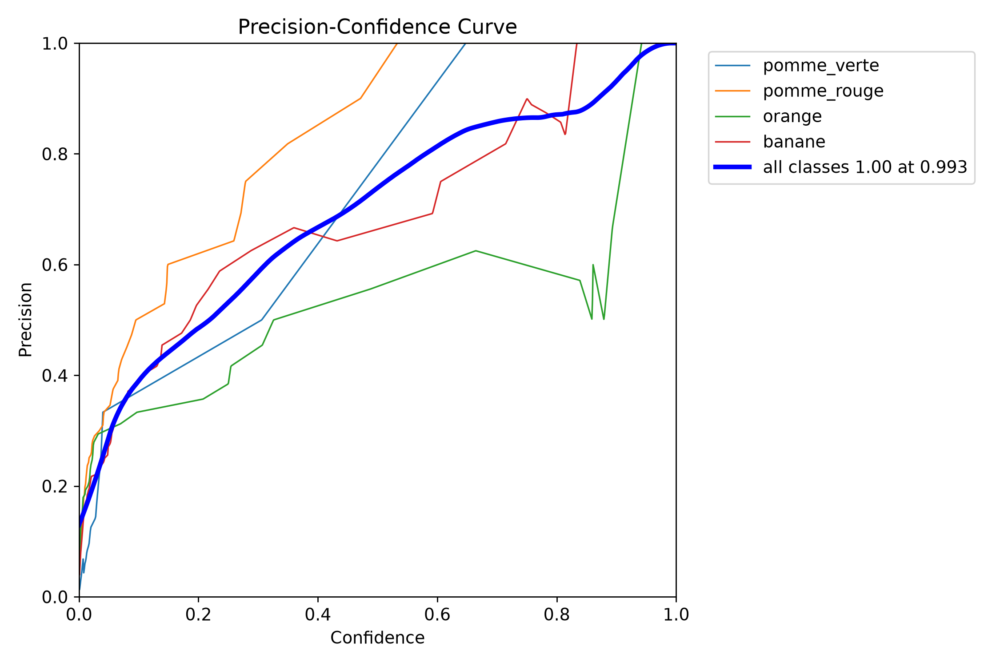


 BoxR_curve.png


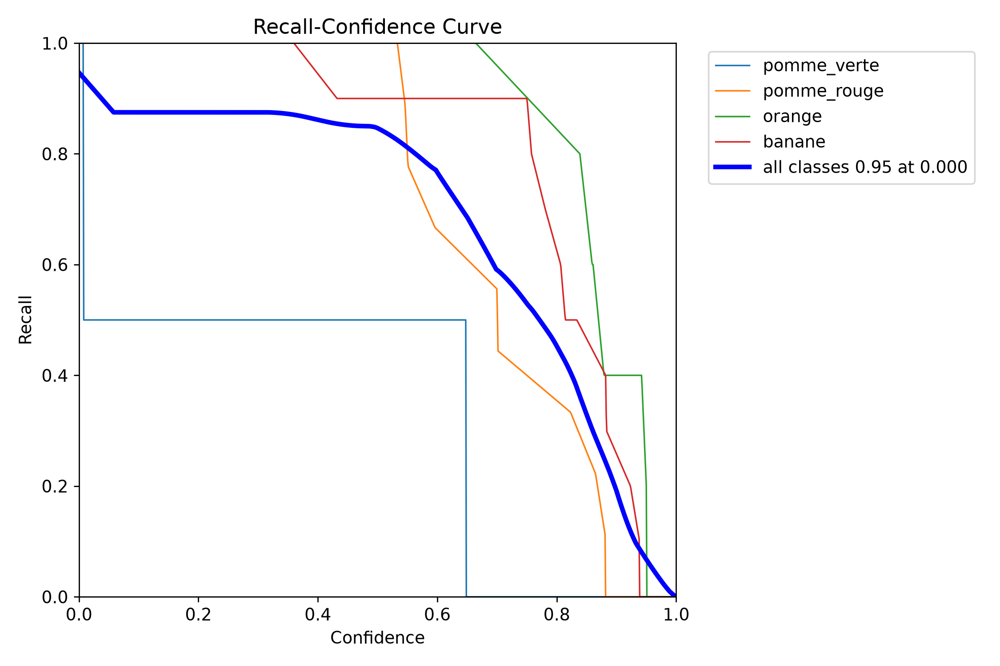

In [32]:
graphiques = [
    "BoxPR_curve.png",
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png"
]

for nom, dossier in {
    "YOLO26n": YOLO26_EVAL,
    "YOLO11n": YOLO11_EVAL
}.items():

    print(f"\n========== {nom} ==========")

    for graphique in graphiques:
        fichier = dossier / graphique

        if fichier.exists():
            print("\n", graphique)
            display(Image(filename=str(fichier), width=750))
        else:
            print("Non disponible :", graphique)


===== MATRICES DE CONFUSION : YOLO26n =====
confusion_matrix.png


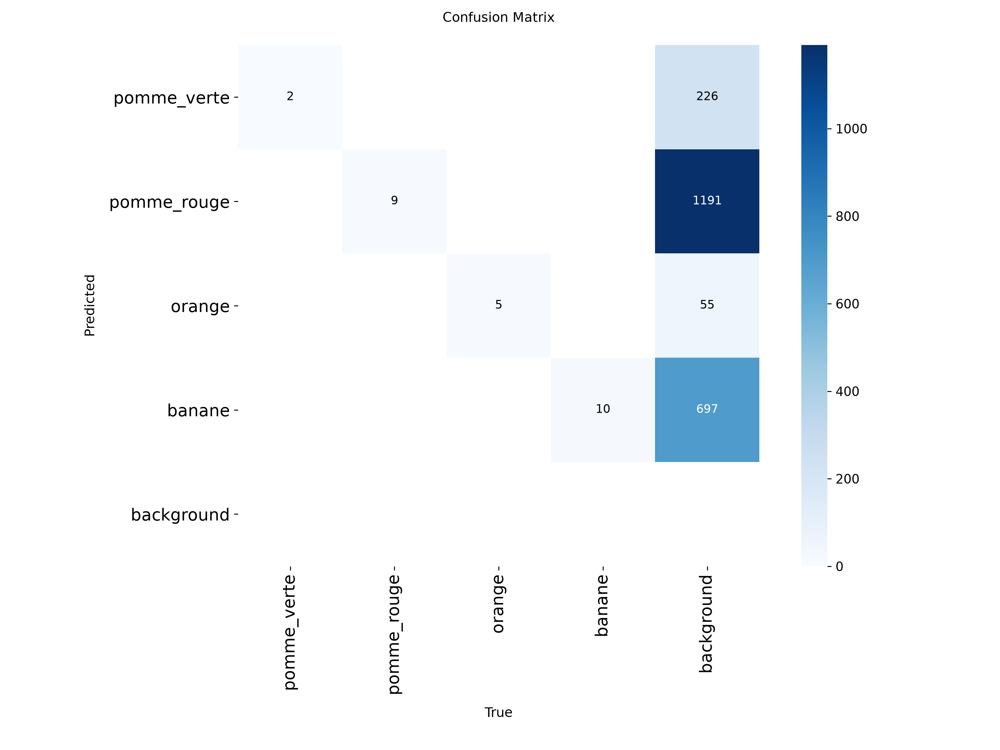

confusion_matrix_normalized.png


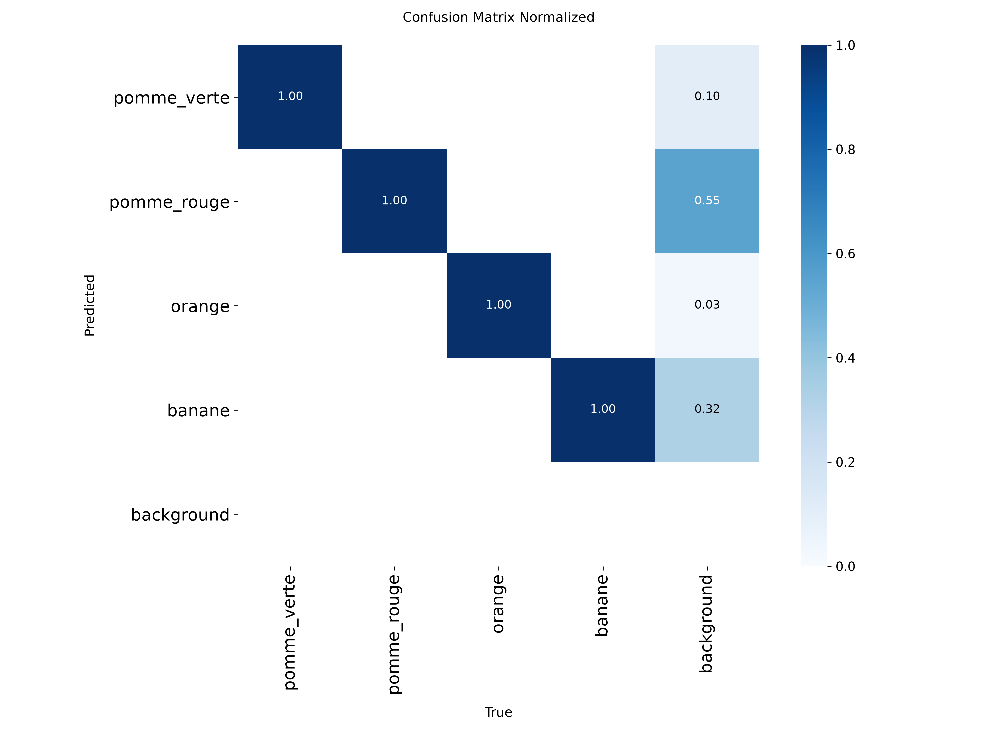


===== MATRICES DE CONFUSION : YOLO11n =====
confusion_matrix.png


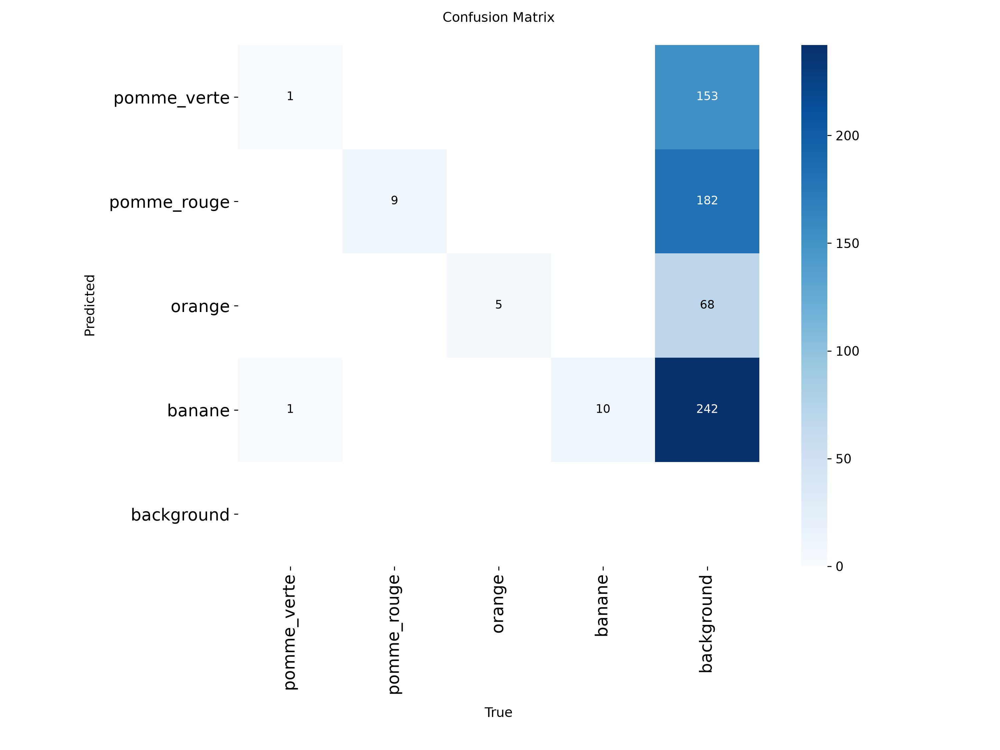

confusion_matrix_normalized.png


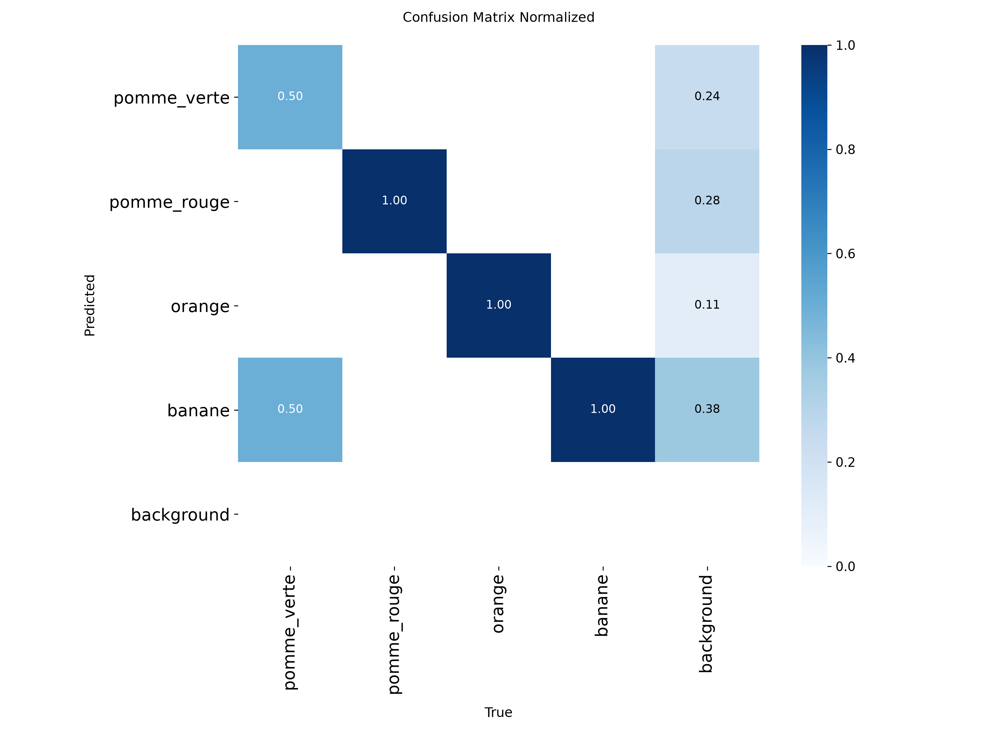

In [33]:
for nom, dossier in {
    "YOLO26n": YOLO26_EVAL,
    "YOLO11n": YOLO11_EVAL
}.items():

    print(f"\n===== MATRICES DE CONFUSION : {nom} =====")

    for graphique in [
        "confusion_matrix.png",
        "confusion_matrix_normalized.png"
    ]:
        fichier = dossier / graphique

        if fichier.exists():
            print(graphique)
            display(Image(filename=str(fichier), width=800))
        else:
            print("Non disponible :", graphique)


===== PRÉDICTIONS YOLO26n =====
Nombre d'images : 22

 image1.jpg


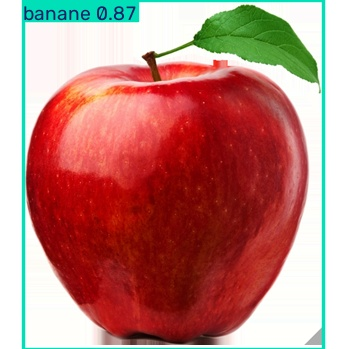


 image10.jpg


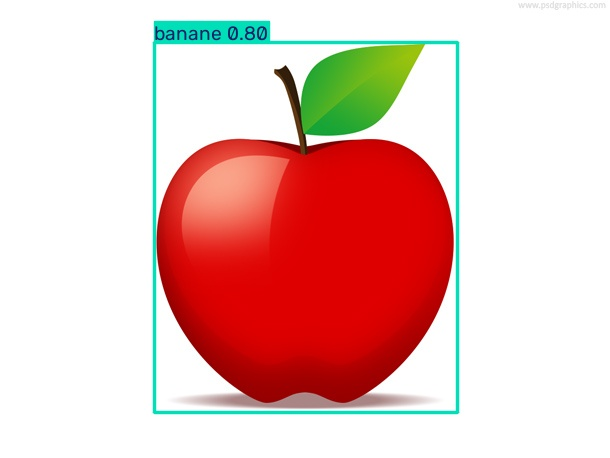


 image11.jpg


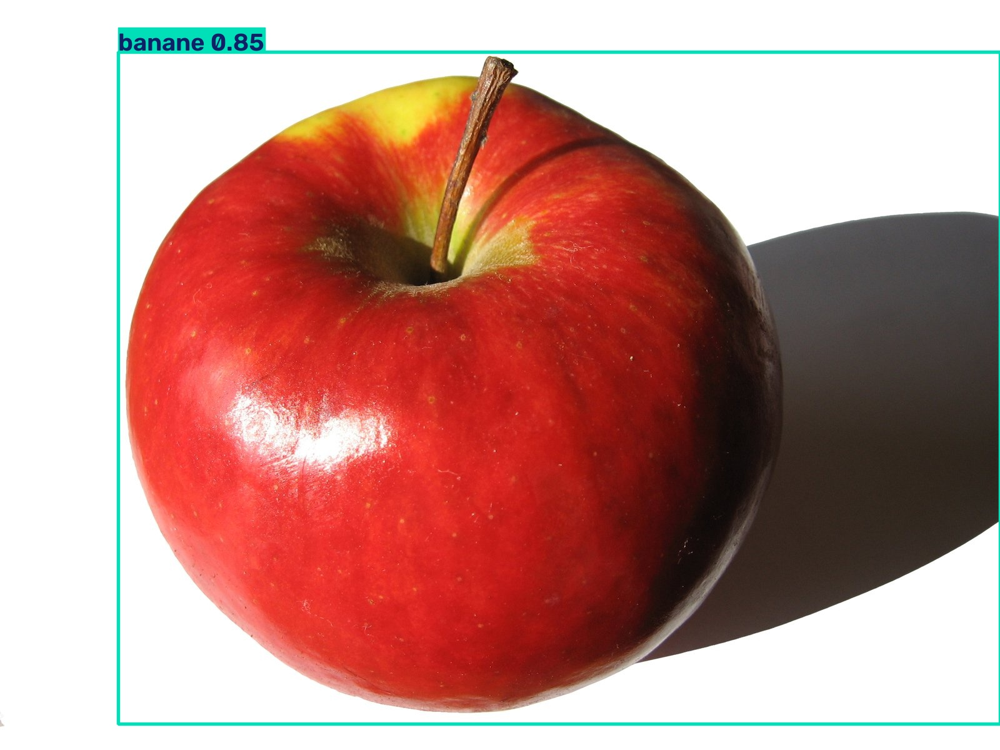


 image12.jpg


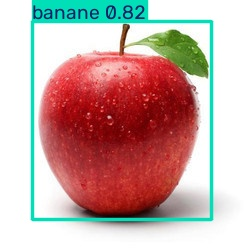


 image153.jpg


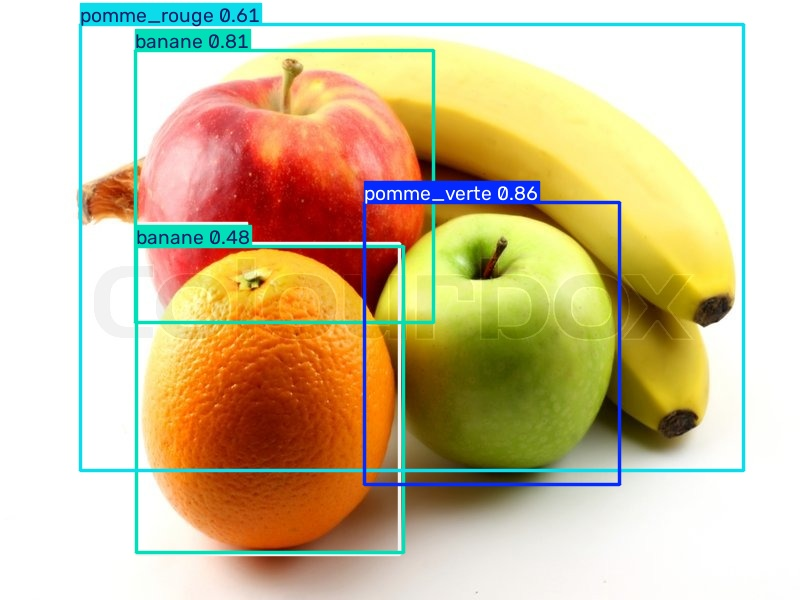


 image154.jpg


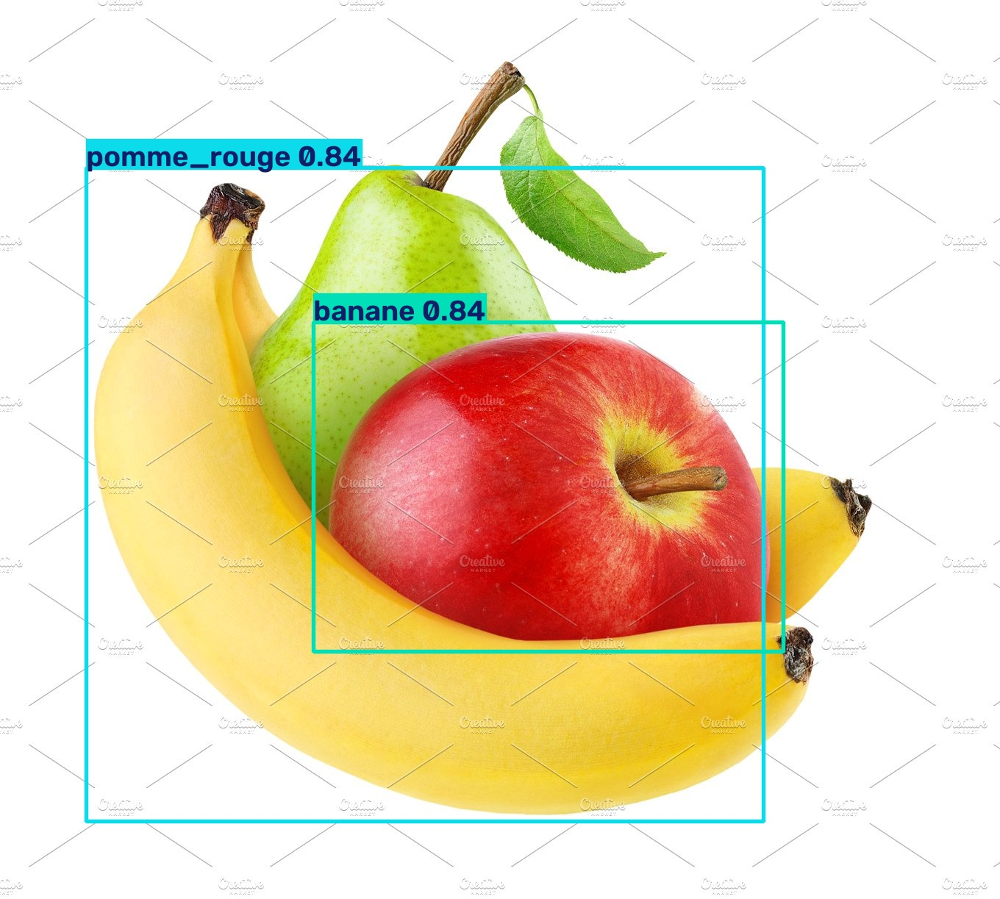


===== PRÉDICTIONS YOLO11n =====
Nombre d'images : 22

 image1.jpg


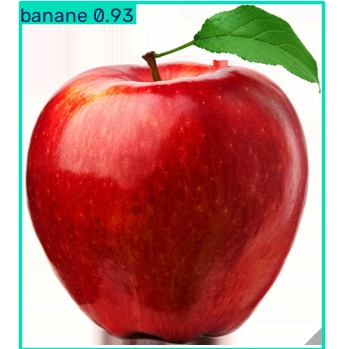


 image10.jpg


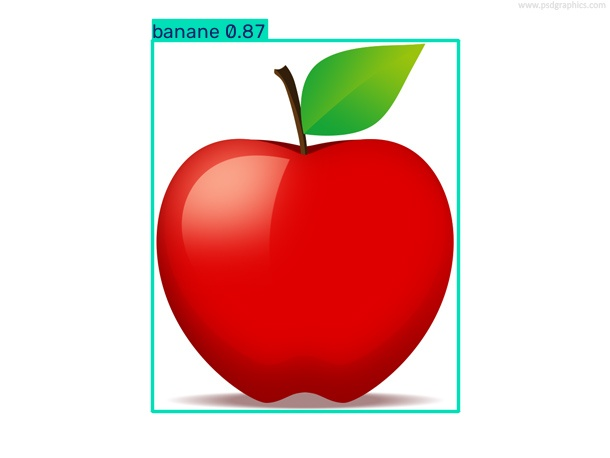


 image11.jpg


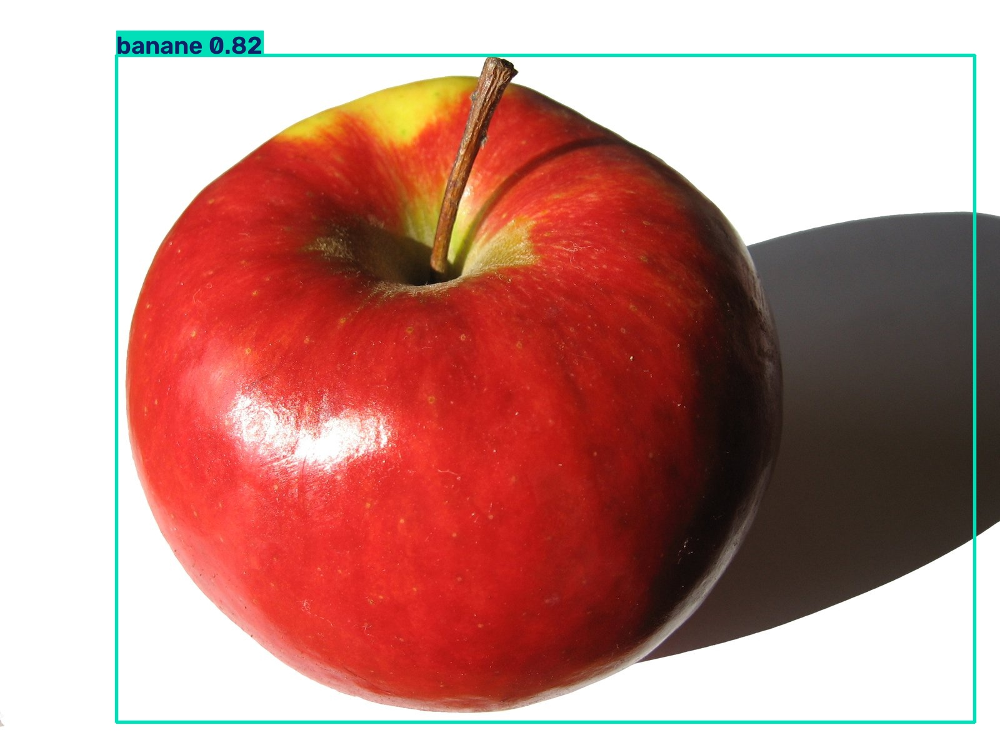


 image12.jpg


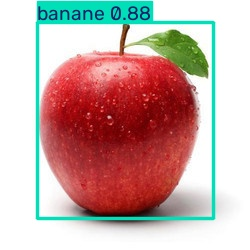


 image153.jpg


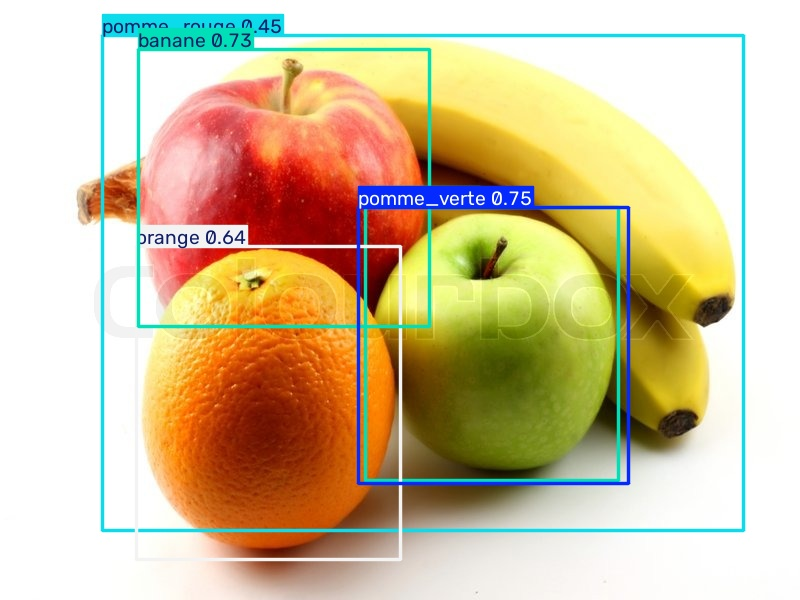


 image154.jpg


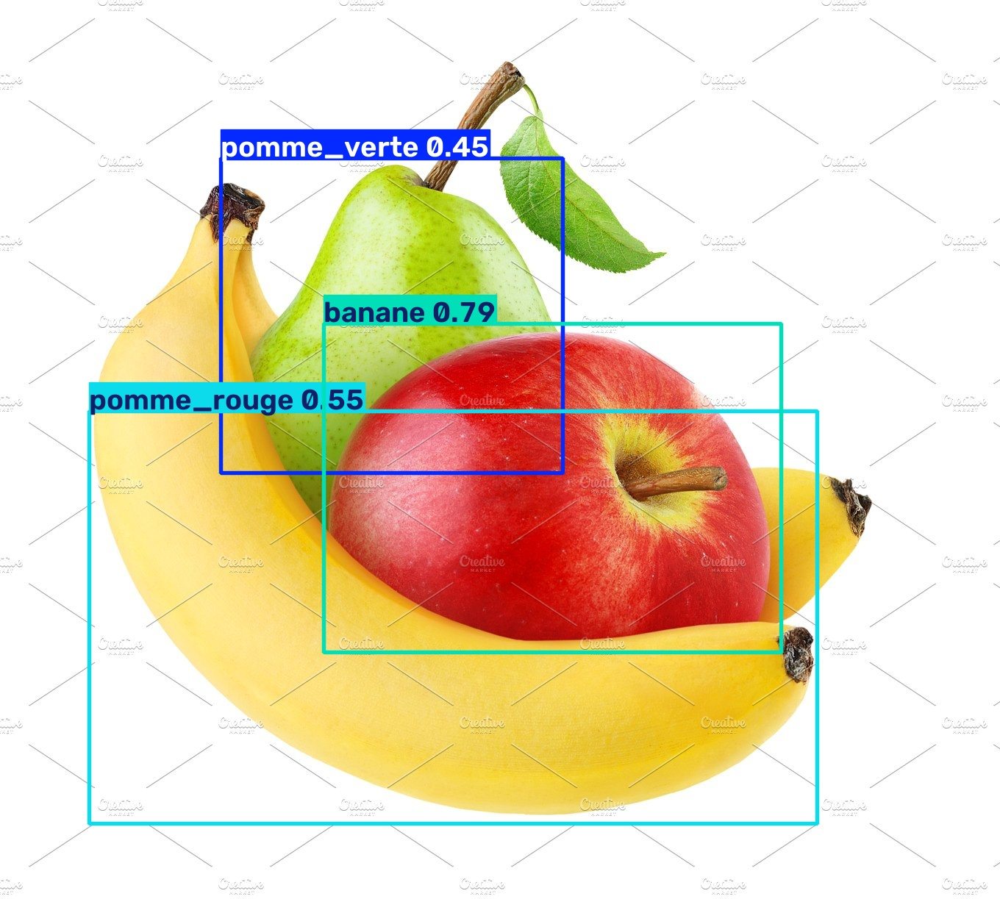

In [34]:
def afficher_predictions(dossier, titre, nombre=6):

    print(f"\n===== {titre} =====")

    if not dossier.exists():
        print("Dossier introuvable :", dossier)
        return

    images = sorted([
        p for p in dossier.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ])

    print("Nombre d'images :", len(images))

    for image in images[:nombre]:
        print("\n", image.name)
        display(Image(filename=str(image), width=650))


afficher_predictions(
    YOLO26_PRED,
    "PRÉDICTIONS YOLO26n"
)

afficher_predictions(
    YOLO11_PRED,
    "PRÉDICTIONS YOLO11n"
)

In [35]:
from ultralytics import YOLO

modeles = {
    "YOLO26n": YOLO26_TRAIN / "weights/best.pt",
    "YOLO11n": YOLO11_TRAIN / "weights/best.pt"
}

resultats = []

for nom, poids in modeles.items():

    if not poids.exists():
        print(f"Poids introuvables pour {nom} : {poids}")
        continue

    print(f"\nÉvaluation de {nom}...")

    model = YOLO(str(poids))

    metrics = model.val(
        data=str(PROJECT_DIR / "dataset_fruits/data.yaml"),
        split="test",
        imgsz=640,
        plots=False,
        project=str(PROJECT_DIR / "evaluation_results"),
        name=f"{nom}_Comparaison",
        exist_ok=True
    )

    precision = metrics.box.mp
    rappel = metrics.box.mr

    f1 = (
        2 * precision * rappel / (precision + rappel)
        if precision + rappel > 0 else 0
    )

    resultats.append({
        "Modèle": nom,
        "Précision": precision,
        "Rappel": rappel,
        "F1 (moyennes)": f1,
        "mAP@50": metrics.box.map50,
        "mAP@50-95": metrics.box.map
    })

df_resultats = pd.DataFrame(resultats)

if not df_resultats.empty:
    display(df_resultats.round(4))
else:
    print("Aucun modèle disponible pour la comparaison.")


Évaluation de YOLO26n...
Ultralytics 8.4.215 🚀 Python-3.14.2 torch-2.15.0+cu132 CPU (Intel Xeon Platinum 8370C CPU @ 2.80GHz)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2372.9±1574.5 MB/s, size: 92.1 KB)
val: Scanning /workspaces/TP2_Labellisation/TP2_Mame_Anta_SARR&&Favour_Tabitha_Gaglozou_YOLO/dataset_fruits/labels/test.cache... 19 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 22/22 4.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.3s/it 2.5s6.4s
                   all         22         26      0.841      0.873      0.902      0.728
           pomme_verte          2          2          1      0.717      0.995       0.57
           pomme_rouge          8          9      0.919      0.889      0.984      0.835
                orange          4          5      0.552      0.986      0.668      0.646
                

,Modèle,Précision,Rappel,F1 (moyennes),mAP@50,mAP@50-95
0,YOLO26n,0.8411,0.8731,0.8568,0.9023,0.7277
1,YOLO11n,0.7543,0.8500,0.7993,0.8050,0.7227


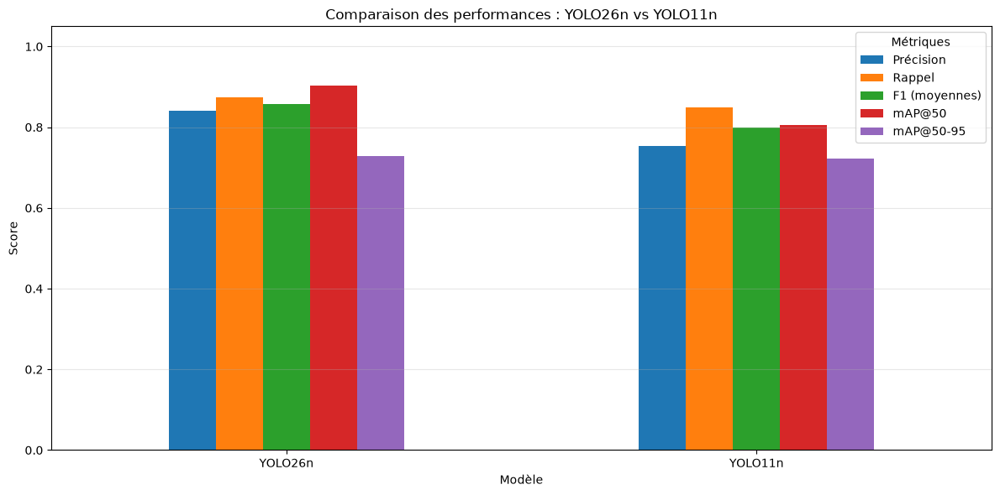

In [36]:
if not df_resultats.empty:

    df_graphique = df_resultats.set_index("Modèle")

    ax = df_graphique[
        ["Précision", "Rappel", "F1 (moyennes)", "mAP@50", "mAP@50-95"]
    ].plot(
        kind="bar",
        figsize=(12, 6),
        rot=0
    )

    ax.set_title("Comparaison des performances : YOLO26n vs YOLO11n")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", alpha=0.3)

    plt.legend(title="Métriques")
    plt.tight_layout()
    plt.show()

else:
    print("Exécute d'abord la cellule 6.")

Images communes : 22


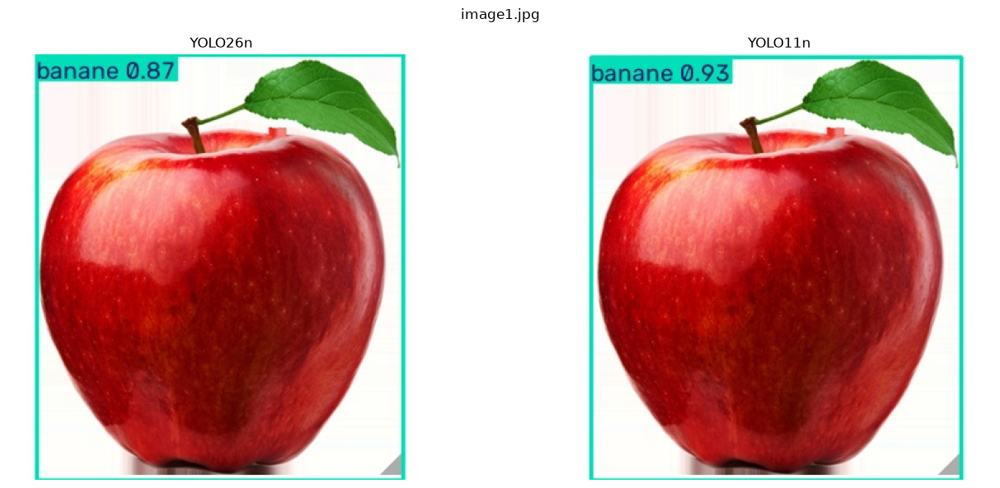

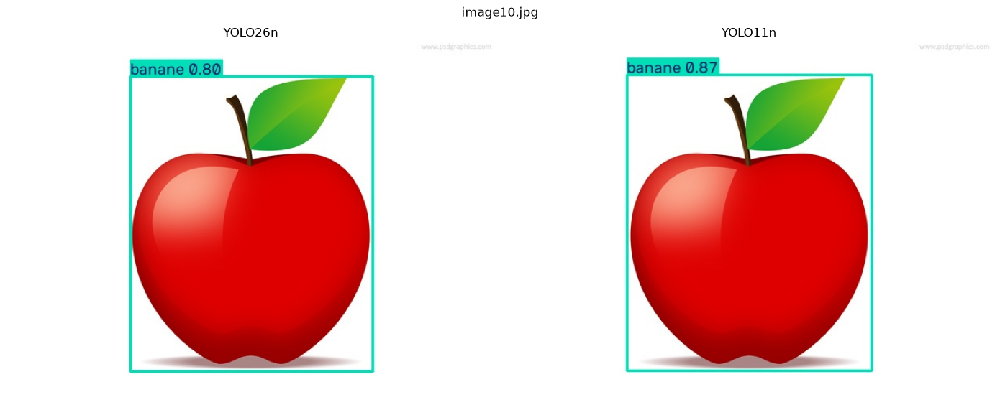

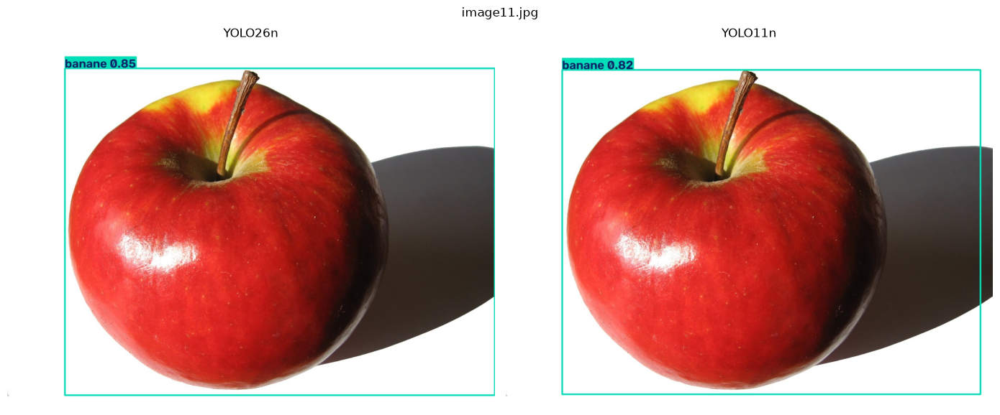

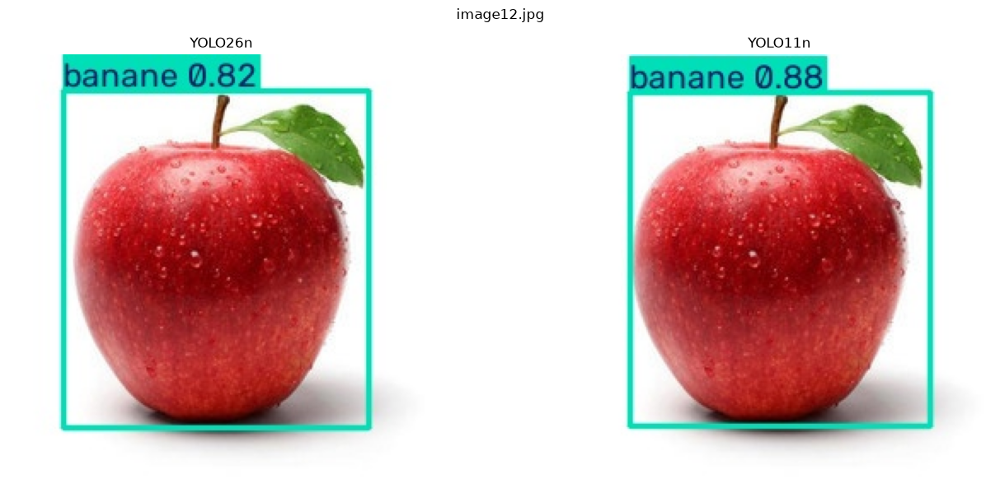

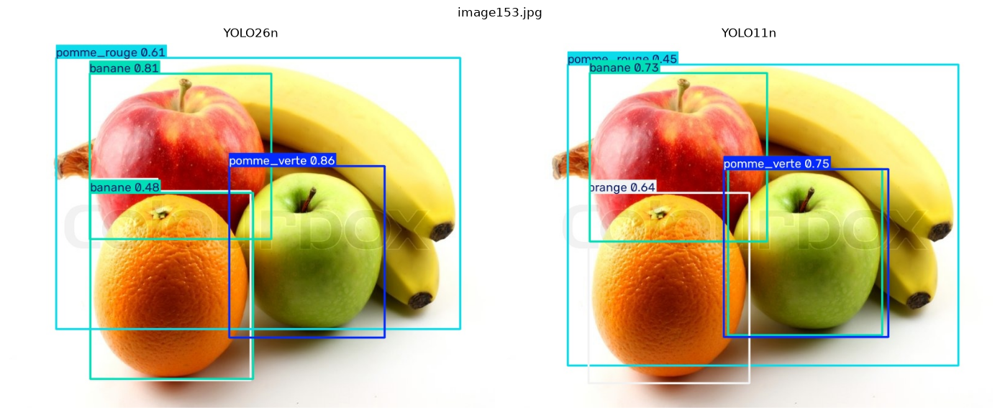

In [37]:
from PIL import Image as PILImage

if YOLO26_PRED.exists() and YOLO11_PRED.exists():

    images26 = {
        p.name: p for p in YOLO26_PRED.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    }

    images11 = {
        p.name: p for p in YOLO11_PRED.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    }

    communes = sorted(set(images26) & set(images11))

    print("Images communes :", len(communes))

    for nom_image in communes[:5]:

        fig, axes = plt.subplots(1, 2, figsize=(14, 6))

        axes[0].imshow(PILImage.open(images26[nom_image]))
        axes[0].set_title("YOLO26n")
        axes[0].axis("off")

        axes[1].imshow(PILImage.open(images11[nom_image]))
        axes[1].set_title("YOLO11n")
        axes[1].axis("off")

        plt.suptitle(nom_image)
        plt.tight_layout()
        plt.show()

else:
    print("Les deux dossiers de prédictions ne sont pas encore disponibles.")